# Spectral Clustering in Machine Learning –

Spectral Clustering is an unsupervised machine learning clustering algorithm used to group similar data points into clusters.

we will explain it with:

- Spectral Clustering fundamentals and working mechanism
- Types and approaches of Spectral Clustering
- Complete Python ML workflow
- Data visualization and EDA
- Training and testing with train-test split
- Evaluation using clustering metrics
- 5 different practical Python examples
- Step-by-step explanation of the code

1. What is Spectral Clustering?

Spectral Clustering is a clustering algorithm that uses graph theory and eigenvectors of a similarity matrix to identify groups in data.

Unlike K-Means, which works well with spherical clusters, Spectral Clustering can identify:

- Circular clusters
- Moon-shaped clusters
- Non-linear clusters
- Complex cluster boundaries
- Connected groups of similar data points

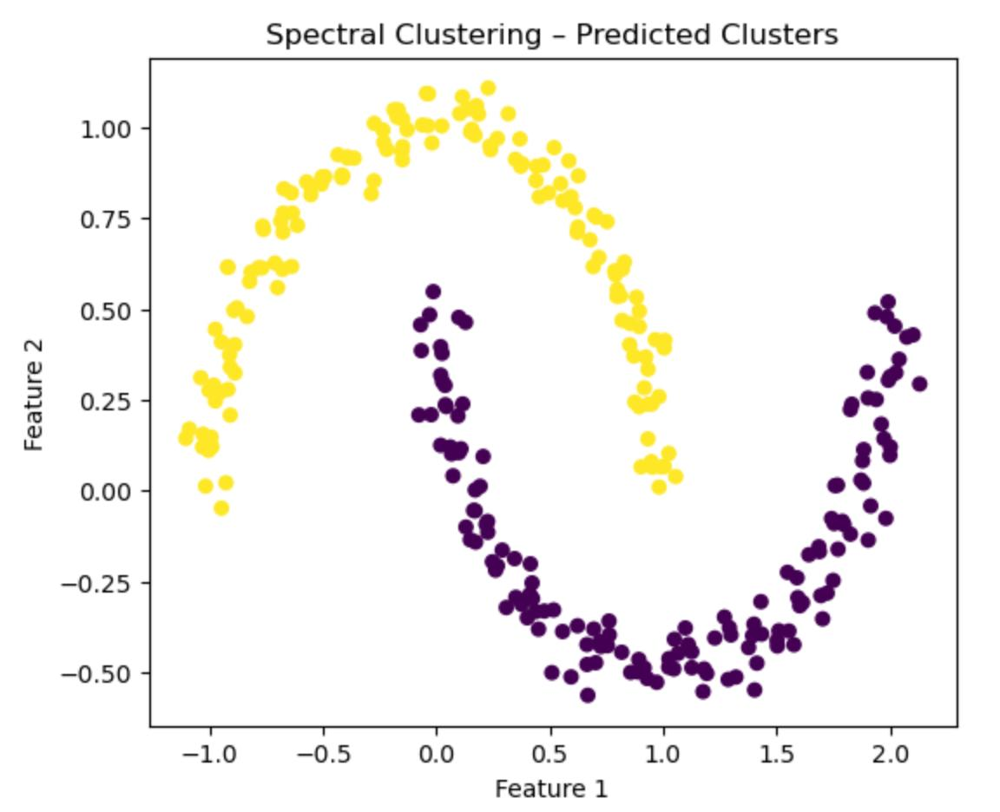
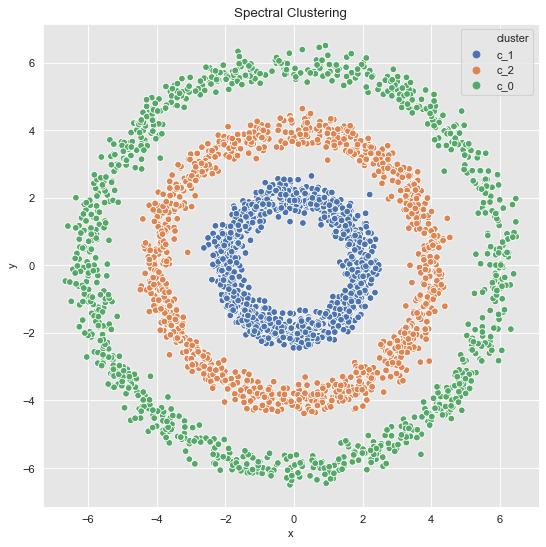
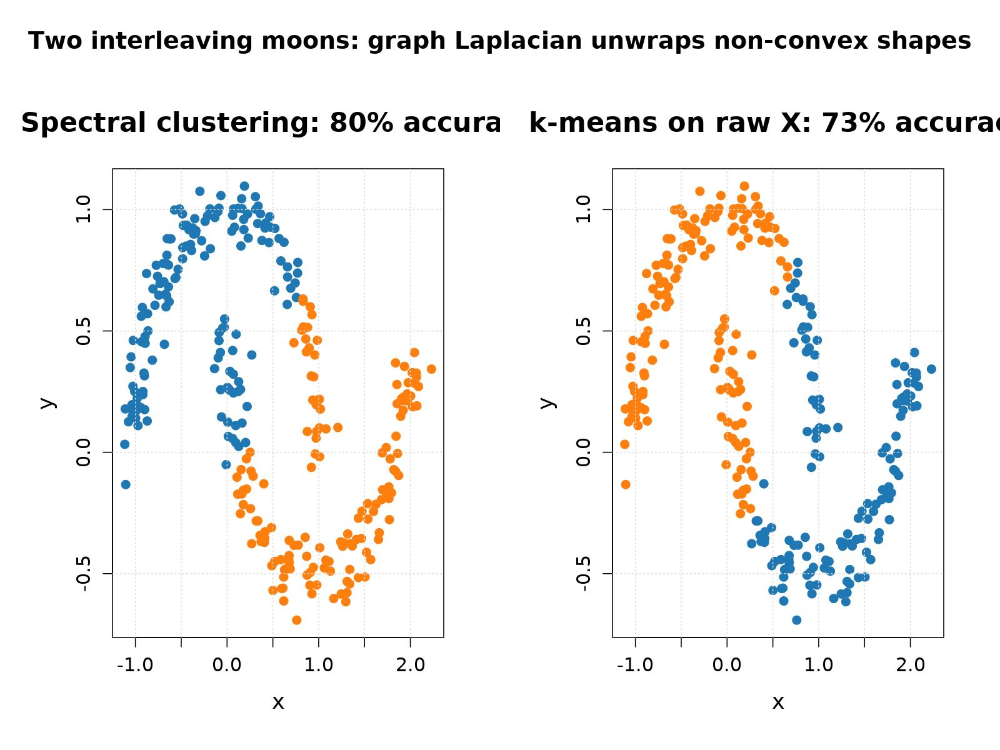
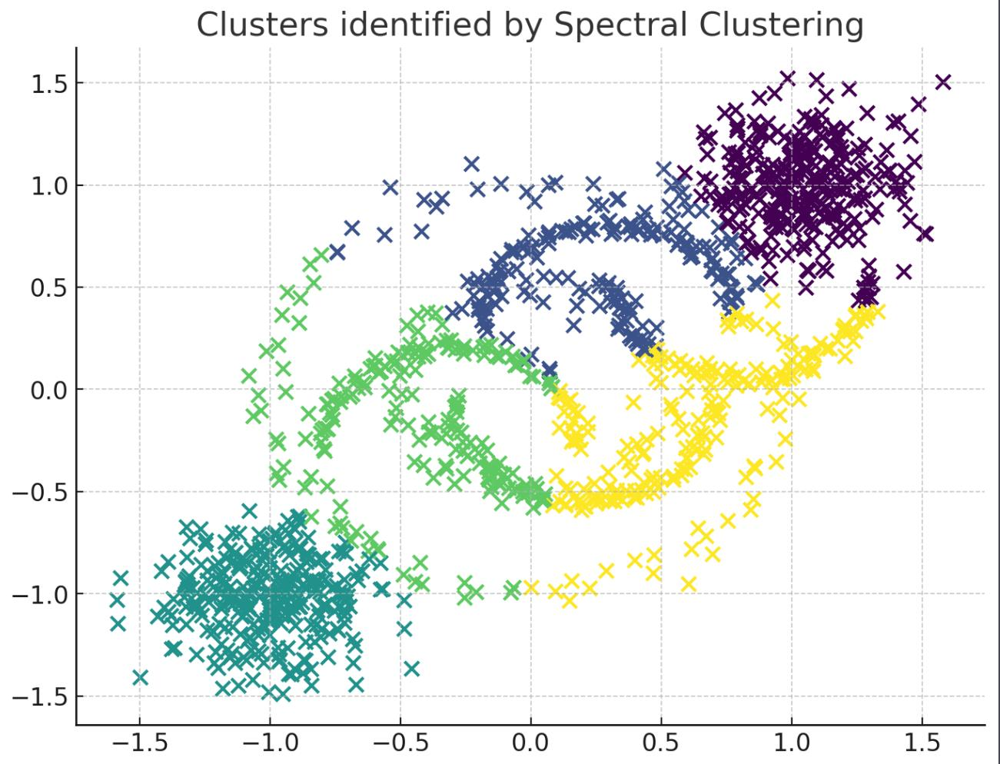
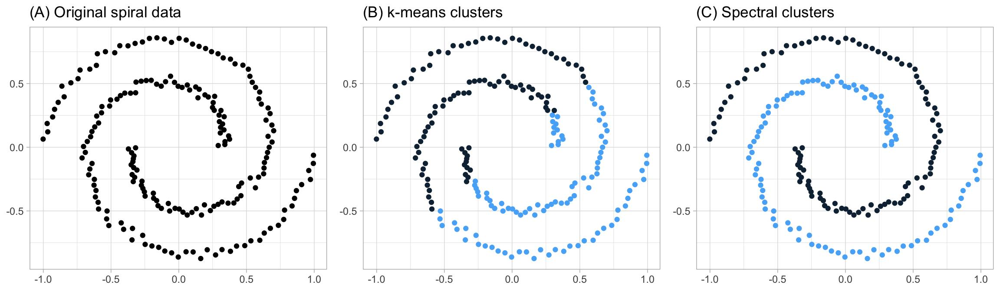
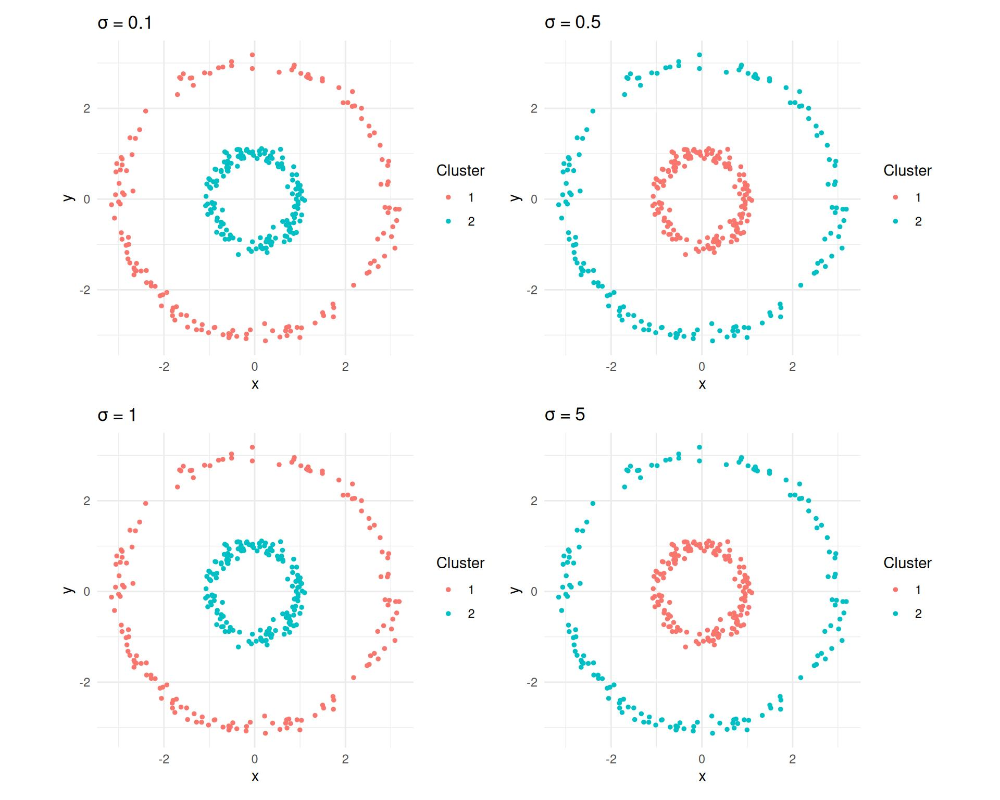



Example

Suppose you have customer data:

Customer|Annual Income|	Spending Score
:-------|-------------|---------------
A|	20,000|	80
B|	22,000|	85
C|	75,000|	30
D|	80,000|	25

Spectral Clustering identifies customers with similar characteristics and assigns them to clusters.

Unlike supervised learning, we don't provide target labels such as customer_segment.

## 2. How Spectral Clustering works

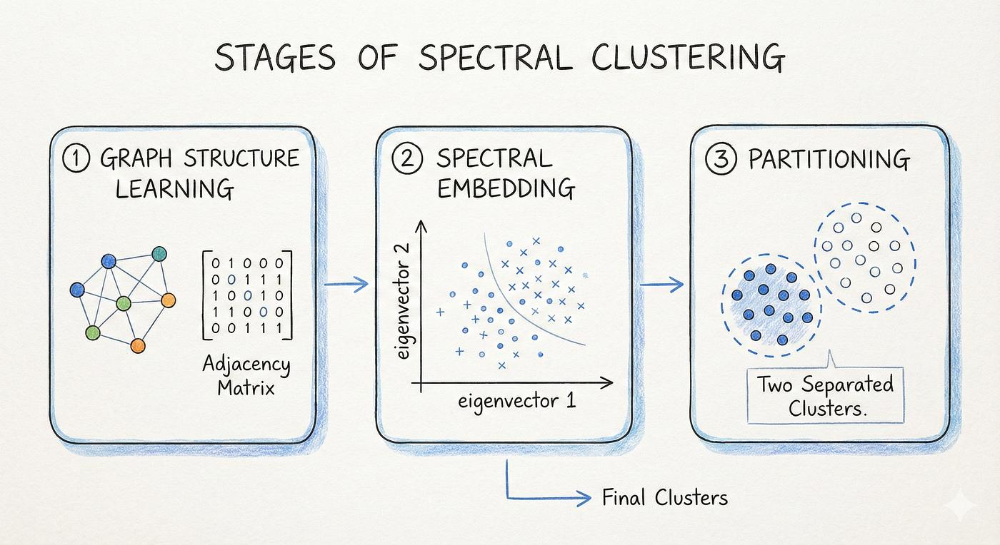

The algorithm typically follows these steps:

Step 1 – Construct a similarity graph

Connect data points based on their similarity.

Step 2 – Build similarity matrix

Calculate how strongly each data point is connected to another.

Step 3 – Calculate degree matrix

Calculate the total similarity connections for each data point.

Step 4 – Calculate graph Laplacian

Construct a matrix representing graph connectivity.

Step 5 – Calculate eigenvectors

Use eigenvectors to transform the original data into a new representation.

Step 6 – Apply K-Means

Cluster the transformed data into the requested number of groups.

## 3. Important mathematical concepts
|Concept|	Meaning
:-------|-----------
Similarity matrix|	Measures similarity between data points
Degree matrix|	Sum of similarities for each point
Graph Laplacian|	Represents graph connectivity
Eigenvalues|	Values describing properties of a matrix
Eigenvectors|	Directions used to represent graph structure
K-Means|	Groups the transformed eigenvector representations

The graph Laplacian is:

\[
L=D-W
\]

Where:
- \(W\) = similarity matrix
- \(D\) = degree matrix
- \(L\) = graph Laplacian
Normalized Laplacian:

\[
L_{sym}=I-D^{-1/2}WD^{-1/2}
\]

4. Types of Spectral Clustering

Spectral Clustering has different approaches depending on how we construct the similarity graph and Laplacian.

|Type|	Description|
:-----|--------------
1.Normalized Spectral Clustering|	Uses normalized graph Laplacian
2.Unnormalized Spectral Clustering|	Uses \(L=D-W\)
3.KNN Graph Spectral Clustering|	Connects nearest neighbors
4.RBF / Gaussian Spectral Clustering|	Uses Gaussian similarity
5.NJW Spectral Clustering|	Uses normalized eigenvectors followed by K-Means

In practice, Scikit-learn's SpectralClustering commonly uses normalized spectral embedding and K-Means-like discretization by default.

Important parameters

|Parameter|	Purpose
:---------|--------------
n_clusters|	Number of clusters
affinity|	Similarity graph construction
gamma|	Controls Gaussian similarity
n_neighbors|	Number of neighbors for KNN graph
assign_labels|	How final cluster labels are assigned
random_state|	Reproducibility

Available affinity options include:
- rbf
- nearest_neighbors
- precomputed
- precomputed_nearest_neighbors

5. Install required Python libraries

Run this in your VS Code terminal:

pip install numpy pandas matplotlib seaborn scikit-learn

## Libraries:

Library|	Purpose
:------|--------------------
NumPy|	Numerical operations
Pandas|	DataFrame and dataset handling
Matplotlib|	Visualization
Seaborn|	Statistical visualization
Scikit-learn|	Spectral Clustering and evaluation

6. Complete ML workflow

1. Problem Understanding


2. Dataset Creation / Loading


3. EDA and Visualization


4. Data Cleaning + Preprocessing


5. Train / Validation Split


6. Build Similarity Graph


7. Spectral Clustering


8. Evaluation + Visualization


9. Cluster Interpretation

Important: Training and testing in clustering

Unlike classification and regression, Spectral Clustering is an unsupervised algorithm.

SpectralClustering in scikit-learn does not provide a normal predict() method for assigning clusters to unseen observations.

Therefore:
- Train-test splitting is not mandatory for ordinary clustering.
- Silhouette Score and other clustering metrics are used for evaluation.
- For unseen data, you need an extension such as Nyström approximation or a separate assignment strategy.


We can still use a train-test split for validation experiments, but we cannot directly call model.predict(X_test).

7. Example 1 – Spectral Clustering using Two Moons Dataset

Problem statement

Create two moon-shaped datasets and identify the two non-linear clusters using Spectral Clustering.

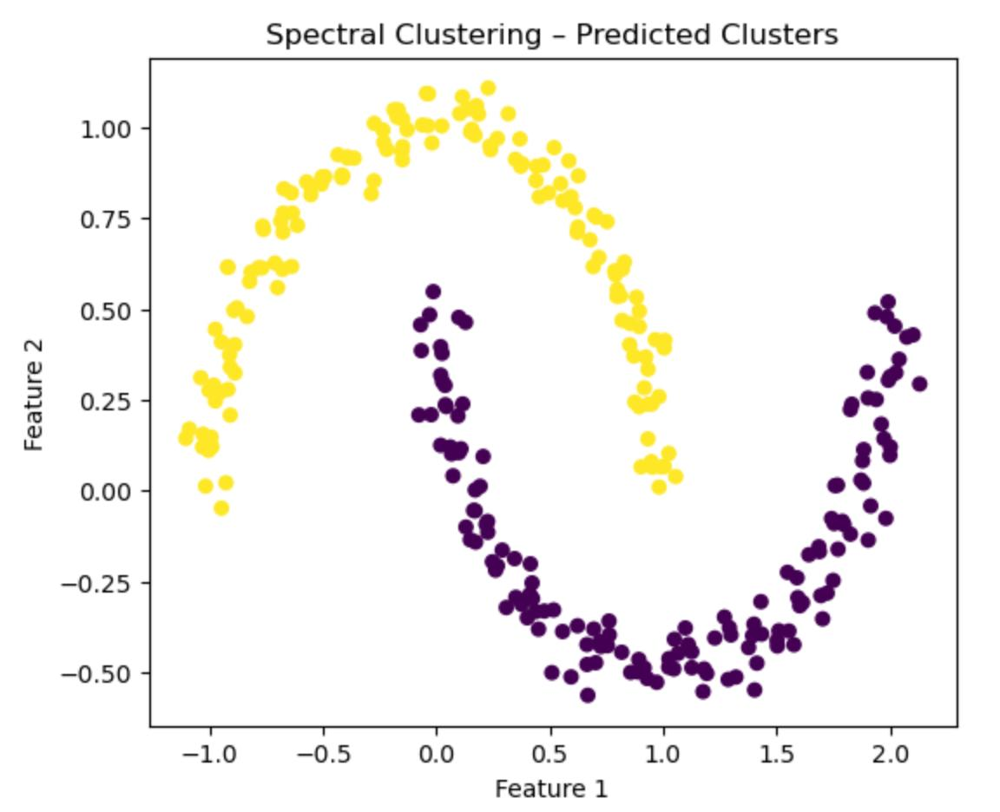

Complete Python code

   Feature1  Feature2
0  0.830640 -0.425055
1  0.759684  0.829335
2  1.039113 -0.488126
3 -0.281591  0.969380
4  0.315699  1.111454
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Feature1  500 non-null    float64
 1   Feature2  500 non-null    float64
dtypes: float64(2)
memory usage: 7.9 KB
None
         Feature1    Feature2
count  500.000000  500.000000
mean     0.507258    0.252147
std      0.872822    0.503921
min     -1.158457   -0.679140
25%     -0.043270   -0.205365
50%      0.471497    0.257724
75%      1.059494    0.697768
max      2.133782    1.190275


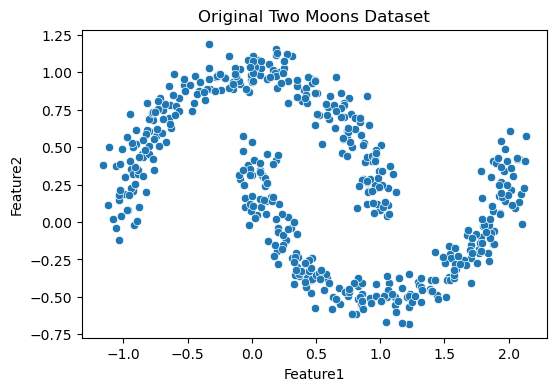

c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


Silhouette Score: 0.38355256771289353


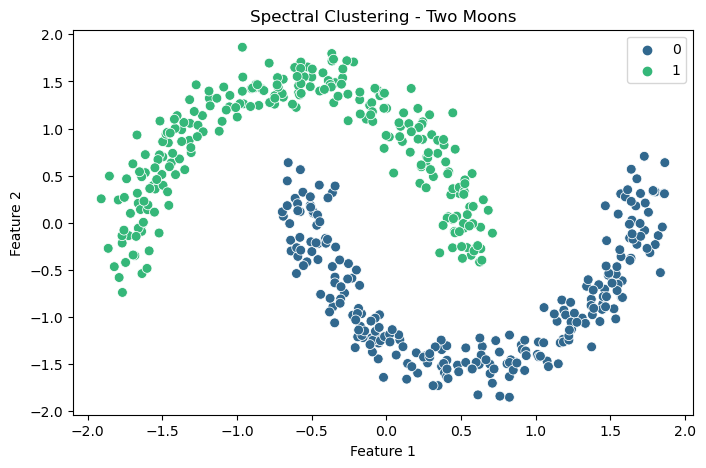

         Feature1  Feature2
Cluster                    
0        1.011041 -0.135822
1        0.003475  0.640115


In [2]:

# ============================================
# EXAMPLE 1: SPECTRAL CLUSTERING - TWO MOONS
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_moons
from sklearn.cluster import SpectralClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# 1. Create dataset
X, y_true = make_moons(
    n_samples=500,
    noise=0.08,
    random_state=42
)

# 2. Convert into DataFrame
df = pd.DataFrame(X, columns=["Feature1", "Feature2"])

# 3. EDA
print(df.head())
print(df.info())
print(df.describe())

# 4. Visualization - original data
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x="Feature1", y="Feature2")
plt.title("Original Two Moons Dataset")
plt.show()

# 5. Preprocessing
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 6. Spectral Clustering
model = SpectralClustering(
    n_clusters=2,
    affinity="rbf",
    gamma=15,
    assign_labels="kmeans",
    random_state=42
)

# 7. Train / fit clustering model
labels = model.fit_predict(X_scaled)

# 8. Add cluster labels
df["Cluster"] = labels

# 9. Evaluation
score = silhouette_score(X_scaled, labels)
print("Silhouette Score:", score)

# 10. Visualization
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_scaled[:, 0],
    y=X_scaled[:, 1],
    hue=labels,
    palette="viridis",
    s=50
)

plt.title("Spectral Clustering - Two Moons")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# 11. Cluster summary
print(df.groupby("Cluster").mean())


Explanation

Step 1 – Create data

In [3]:
X, y_true = make_moons(
    n_samples=500,
    noise=0.08,
    random_state=42
)

- n_samples=500: creates 500 observations.
- noise=0.08: adds small random noise.
- random_state=42: ensures reproducible results.

y_true contains the original synthetic class labels, which we can use for optional external evaluation.

Step 2 – Scale features

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Why scaling?

Spectral Clustering uses similarity between observations. Large-scale features can distort the similarity calculation.

Step 3 – Apply Spectral Clustering

In [5]:
model = SpectralClustering(
    n_clusters=2,
    affinity="rbf",
    gamma=15
)

n_clusters=2: identifies two groups.



affinity="rbf": uses Gaussian similarity.



gamma=15: controls how quickly similarity decreases with distance.

Step 4 – Fit and generate labels

In [6]:
labels = model.fit_predict(X_scaled)

c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


Each observation receives a cluster number.


Step 5 – Evaluation

In [7]:
silhouette_score(X_scaled, labels)

0.38355256771289353

The Silhouette Score measures how well-separated the clusters are.

- Close to 1: good separation.
- Close to 0: overlapping clusters.
- Negative: some observations may be assigned to unsuitable clusters

8. Example 2 – Customer Segmentation

Problem statement
A retail company wants to segment customers based on:
- Annual Income
- Spending Score
- Age

Use Spectral Clustering to identify customer groups.

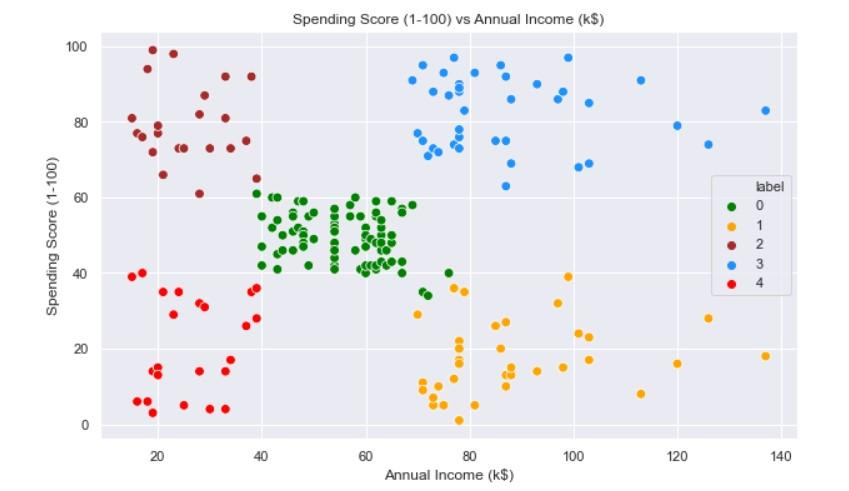

   Age  Annual_Income  Spending_Score
0   56          53467              55
1   46          38328              13
2   32         106412              23
3   60         101831              89
4   25          18987              99
              Age  Annual_Income  Spending_Score
count  300.000000     300.000000      300.000000
mean    40.810000   69152.216667       49.836667
std     13.547164   30842.858187       28.941354
min     18.000000   15301.000000        1.000000
25%     29.000000   42729.000000       23.750000
50%     41.500000   70178.500000       51.000000
75%     52.000000   97746.250000       75.000000
max     64.000000  119290.000000       99.000000
Age               0
Annual_Income     0
Spending_Score    0
dtype: int64


c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


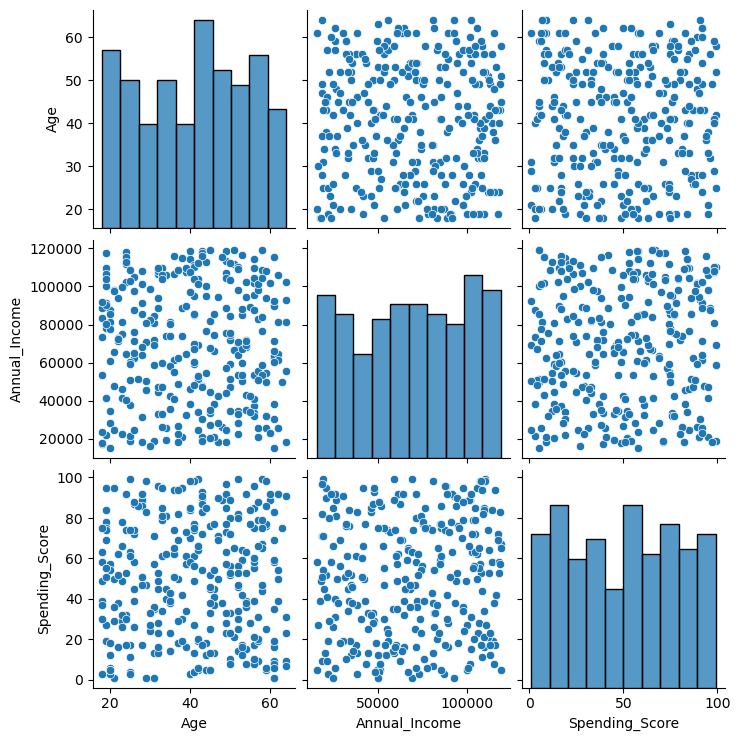

c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


Silhouette Score: 0.26429523524053783


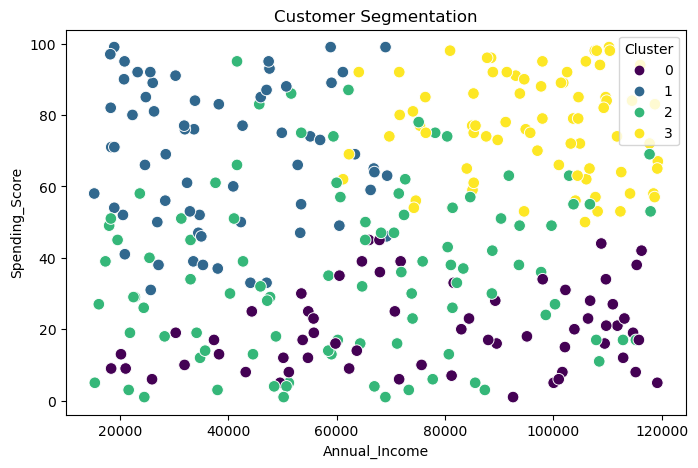

               Age  Annual_Income  Spending_Score
Cluster                                          
0        51.873016   77522.238095       19.984127
1        48.859375   38845.015625       68.500000
2        26.785714   62640.346939       36.367347
3        42.973333   96492.386667       76.586667


In [8]:

# ============================================
# EXAMPLE 2: CUSTOMER SEGMENTATION
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import SpectralClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

np.random.seed(42)

# 1. Generate sample customer dataset
n = 300

df = pd.DataFrame({
    "Age": np.random.randint(18, 65, n),
    "Annual_Income": np.random.randint(15000, 120000, n),
    "Spending_Score": np.random.randint(1, 100, n)
})

# 2. EDA
print(df.head())
print(df.describe())
print(df.isnull().sum())

sns.pairplot(df)
plt.show()

# 3. Feature selection
X = df[["Age", "Annual_Income", "Spending_Score"]]

# 4. Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Spectral Clustering
model = SpectralClustering(
    n_clusters=4,
    affinity="nearest_neighbors",
    n_neighbors=15,
    assign_labels="kmeans",
    random_state=42
)

df["Cluster"] = model.fit_predict(X_scaled)

# 6. Evaluation
print("Silhouette Score:",
      silhouette_score(X_scaled, df["Cluster"]))

# 7. Visualization
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Annual_Income",
    y="Spending_Score",
    hue="Cluster",
    palette="viridis",
    s=70
)

plt.title("Customer Segmentation")
plt.show()

# 8. Cluster profiling
print(df.groupby("Cluster").mean())


Business interpretation

Cluster profile|	Possible interpretation
:---------------|---------------------------
High income + high spending|	Premium customers
High income + low spending|	Potential customers
Low income + high spending|	Active budget shoppers
Low income + low spending|	Low-spending customers

Note: These are possible interpretations, not guaranteed cluster meanings. Actual cluster profiles must be examined.

9. Example 3 – Student Performance Clustering

Problem statement
A school wants to group students based on:
- Study Hours
- Attendance
- Exam Score

The objective is to identify student performance patterns.

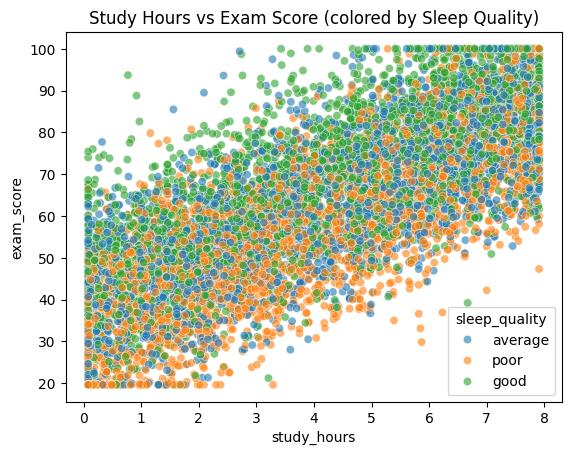

Complete Python code

   Study_Hours  Attendance  Exam_Score
0     4.370861   52.584086   41.825454
1     9.556429   76.567732   49.501324
2     7.587945   77.031756   42.390734
3     6.387926   81.871495   36.209177
4     2.404168   86.304567   38.444511
       Study_Hours  Attendance  Exam_Score
count   300.000000  300.000000  300.000000
mean      5.456841   75.541575   62.976226
std       2.649065   15.129518   19.839924
min       1.045554   50.541883   30.324242
25%       3.151727   62.480746   44.683657
50%       5.605460   76.085139   61.700492
75%       7.811737   88.667102   80.189181
max       9.910485   99.985884   99.781198


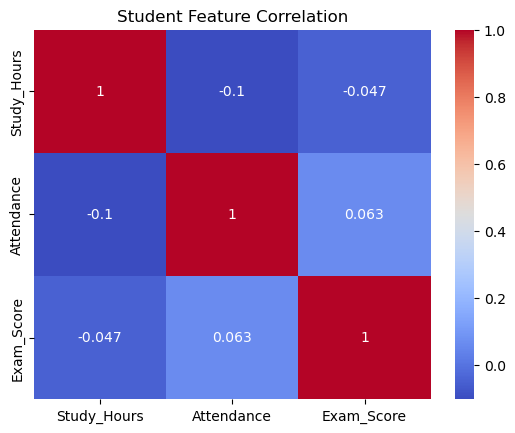

c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


Silhouette Score: 0.26332979695663083


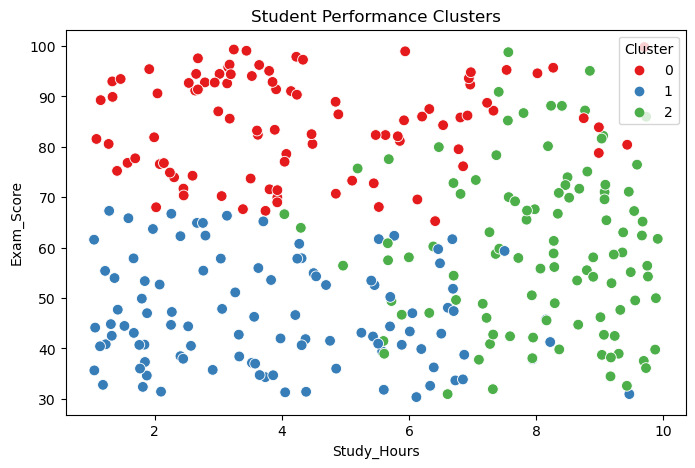

         Study_Hours  Attendance  Exam_Score
Cluster                                     
0           4.323952   81.170040   84.535007
1           3.904156   79.384895   46.570367
2           8.043427   66.561598   59.707081


In [9]:

# ============================================
# EXAMPLE 3: STUDENT PERFORMANCE
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import SpectralClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

np.random.seed(42)

# 1. Dataset
n = 300

df = pd.DataFrame({
    "Study_Hours": np.random.uniform(1, 10, n),
    "Attendance": np.random.uniform(50, 100, n),
    "Exam_Score": np.random.uniform(30, 100, n)
})

# 2. EDA
print(df.head())
print(df.describe())

sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Student Feature Correlation")
plt.show()

# 3. Features
X = df[[
    "Study_Hours",
    "Attendance",
    "Exam_Score"
]]

# 4. Preprocessing
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Spectral Clustering
model = SpectralClustering(
    n_clusters=3,
    affinity="rbf",
    gamma=1,
    random_state=42
)

df["Cluster"] = model.fit_predict(X_scaled)

# 6. Evaluation
print("Silhouette Score:",
      silhouette_score(X_scaled, df["Cluster"]))

# 7. Visualization
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Study_Hours",
    y="Exam_Score",
    hue="Cluster",
    palette="Set1",
    s=60
)

plt.title("Student Performance Clusters")
plt.show()

# 8. Cluster analysis
print(df.groupby("Cluster").mean())


Interpretation

You may discover groups such as:
- High study hours + high scores
- Moderate study hours + moderate scores
- Low study hours + lower scores

This can help educational institutions identify students who may benefit from additional academic support.

10. Example 4 – Employee Analytics Clustering

Problem statement

An HR department wants to group employees based on:
- Experience
- Monthly Working Hours
- Performance Score

Objective: identify employee patterns for workforce planning.

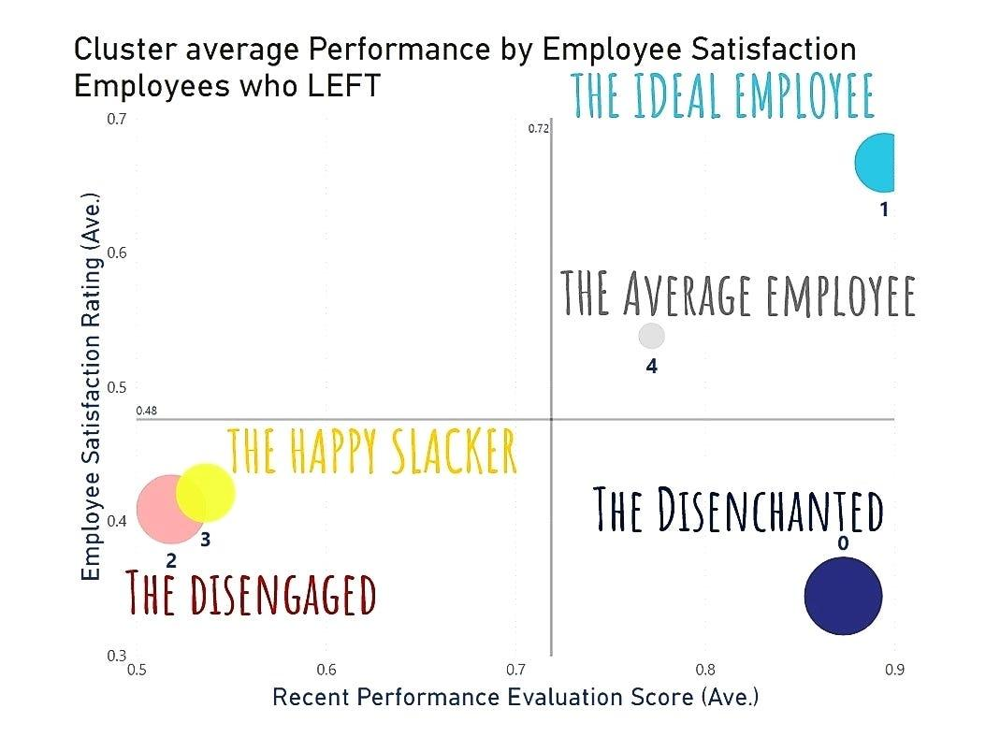

Complete Python code

   Experience  Working_Hours  Performance
0           6            144     3.113480
1          19            173     2.745343
2          14            177     4.208437
3          10            186     4.911603
4           7            223     3.224020
       Experience  Working_Hours  Performance
count  300.000000     300.000000   300.000000
mean     8.930000     213.236667     3.022831
std      6.088404      51.799853     1.131801
min      0.000000     120.000000     1.010380
25%      3.000000     171.000000     2.071955
50%      8.000000     217.500000     3.122212
75%     15.000000     259.250000     3.953677
max     19.000000     299.000000     4.990770


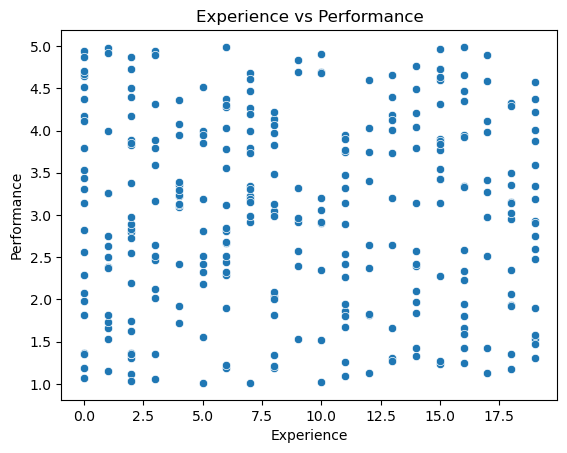

c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


Silhouette Score: 0.21861879426889147


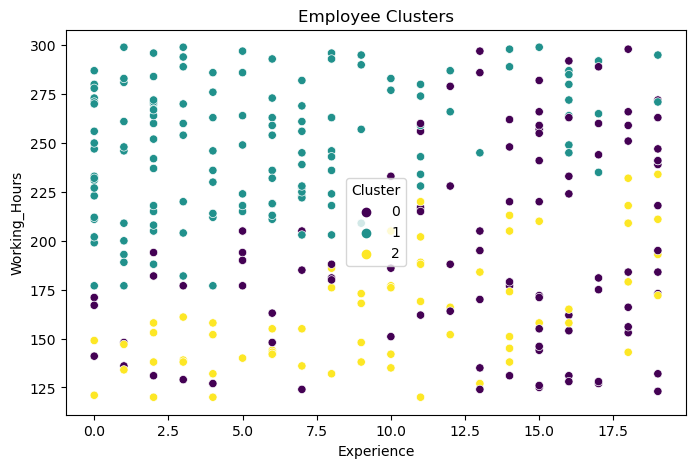

         Experience  Working_Hours  Performance
Cluster                                        
0         12.635417     196.260417     4.022523
1          5.846715     248.759124     2.760983
2          9.925373     164.925373     2.125855


In [10]:

# ============================================
# EXAMPLE 4: EMPLOYEE ANALYTICS
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import SpectralClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

np.random.seed(42)

# 1. Dataset
n = 300

df = pd.DataFrame({
    "Experience": np.random.randint(0, 20, n),
    "Working_Hours": np.random.randint(120, 300, n),
    "Performance": np.random.uniform(1, 5, n)
})

# 2. EDA
print(df.head())
print(df.describe())

sns.scatterplot(
    data=df,
    x="Experience",
    y="Performance"
)
plt.title("Experience vs Performance")
plt.show()

# 3. Features
X = df[[
    "Experience",
    "Working_Hours",
    "Performance"
]]

# 4. Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Model
model = SpectralClustering(
    n_clusters=3,
    affinity="nearest_neighbors",
    n_neighbors=10,
    random_state=42
)

df["Cluster"] = model.fit_predict(X_scaled)

# 6. Evaluation
print("Silhouette Score:",
      silhouette_score(X_scaled, df["Cluster"]))

# 7. Visualization
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Experience",
    y="Working_Hours",
    hue="Cluster",
    palette="viridis"
)

plt.title("Employee Clusters")
plt.show()

# 8. Cluster profiling
print(df.groupby("Cluster").mean())


Interpretation

Possible employee groups:

- Experienced employees with high performance
- Employees working longer hours
- Employees with moderate experience and performance

HR can use this analysis for workforce planning and development.

11. Example 5 – E-Commerce Product Clustering

Problem statement

An e-commerce company wants to group products based on:
- Product Price
- Sales Volume
- Product Rating

Objective: discover product categories based on purchasing behavior.

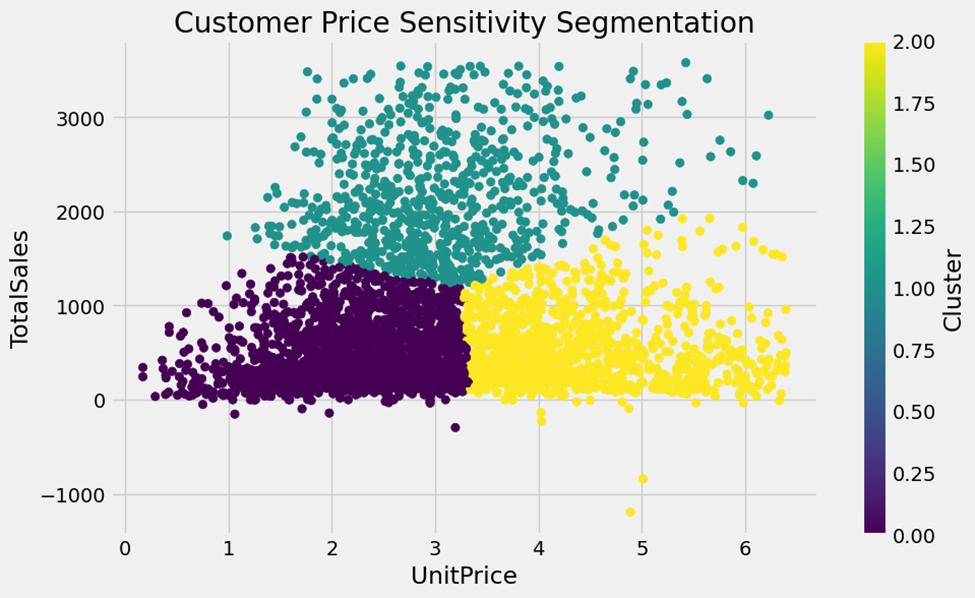

Complete Python code

         Price  Sales    Rating
0  3807.947177    877  2.737807
1  9512.071633    992  2.014729
2  7346.740024    884  2.620808
3  6026.718994    350  3.285892
4  1644.584540     47  3.963895
             Price       Sales      Rating
count   300.000000  300.000000  300.000000
mean   5002.525531  504.923333    3.009132
std    2913.971341  290.968991    1.123645
min     150.109680    9.000000    1.010380
25%    2466.899960  236.500000    2.071955
50%    5166.005513  512.000000    3.103945
75%    7592.910199  758.250000    3.948707
max    9901.533116  999.000000    4.989022
Price     0
Sales     0
Rating    0
dtype: int64


c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


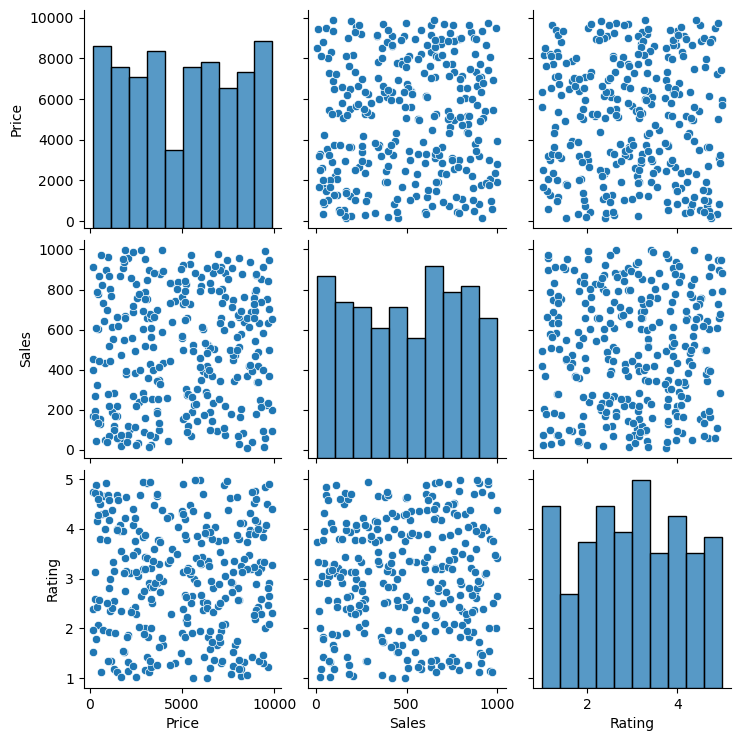

c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


Silhouette Score: 0.27373047323672384


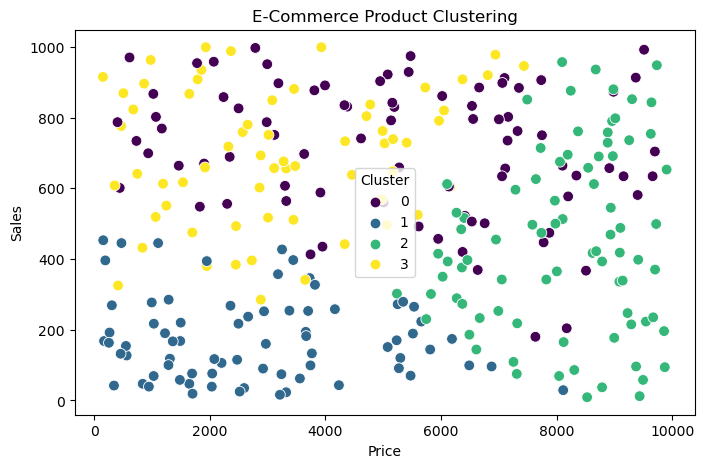

               Price       Sales    Rating
Cluster                                   
0        5243.801003  712.876543  1.877041
1        2810.527037  176.094595  2.773814
2        8120.506837  449.170732  3.464915
3        3208.717726  696.365079  4.147841


In [11]:

# ============================================
# EXAMPLE 5: E-COMMERCE PRODUCT CLUSTERING
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import SpectralClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

np.random.seed(42)

# 1. Dataset
n = 300

df = pd.DataFrame({
    "Price": np.random.uniform(100, 10000, n),
    "Sales": np.random.randint(1, 1000, n),
    "Rating": np.random.uniform(1, 5, n)
})

# 2. EDA
print(df.head())
print(df.describe())
print(df.isnull().sum())

sns.pairplot(df)
plt.show()

# 3. Features
X = df[["Price", "Sales", "Rating"]]

# 4. Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Spectral Clustering
model = SpectralClustering(
    n_clusters=4,
    affinity="rbf",
    gamma=0.5,
    random_state=42
)

df["Cluster"] = model.fit_predict(X_scaled)

# 6. Evaluation
print("Silhouette Score:",
      silhouette_score(X_scaled, df["Cluster"]))

# 7. Visualization
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Price",
    y="Sales",
    hue="Cluster",
    palette="viridis",
    s=60
)

plt.title("E-Commerce Product Clustering")
plt.show()

# 8. Cluster profiling
print(df.groupby("Cluster").mean())


Interpretation

Possible product groups:
- High-price products
- Low-price high-volume products
- Highly rated products
- Low-sales products

This can support product recommendations, inventory planning, and marketing strategies.

12. Train-Test Split in Spectral Clustering

In supervised ML:

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

NameError: name 'train_test_split' is not defined

But in Spectral Clustering, there is no standard predict() for test observations.

A practical alternative is to split the data and independently cluster each partition for exploratory stability analysis.

In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.cluster import SpectralClustering
from sklearn.preprocessing import StandardScaler

# X is your feature matrix

X_train, X_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

# Scale using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Fit clustering on training subset
train_model = SpectralClustering(
    n_clusters=3,
    affinity="rbf",
    random_state=42
)

train_labels = train_model.fit_predict(X_train_scaled)

# Independently cluster test subset
test_model = SpectralClustering(
    n_clusters=3,
    affinity="rbf",
    random_state=42
)

test_labels = test_model.fit_predict(X_test_scaled)

print("Train clusters:", train_labels)
print("Test clusters:", test_labels)


c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Train clusters: [0 1 1 2 2 2 1 2 1 2 1 2 2 2 2 0 0 0 0 0 1 2 2 0 1 1 2 0 1 0 1 2 0 1 1 1 2
 2 1 2 2 2 1 2 1 0 1 2 0 2 0 0 2 2 2 2 2 2 1 0 2 1 1 0 2 0 2 2 0 0 2 2 1 0
 2 2 1 1 2 2 2 1 1 1 2 2 2 2 0 1 1 1 0 1 2 1 0 2 2 0 1 2 2 2 1 1 0 2 1 2 1
 1 2 2 1 0 0 0 0 0 2 1 0 2 0 1 2 0 1 2 1 2 1 0 2 2 2 2 2 2 0 0 1 1 2 0 0 0
 2 1 0 1 1 2 2 0 0 1 2 0 1 1 2 2 0 1 0 0 2 2 1 2 0 0 2 1 2 2 0 1 2 1 2 2 1
 1 1 0 2 2 1 1 0 2 2 2 1 2 0 2 2 2 2 0 1 1 0 2 0 0 2 2 2 0 1 1 2 0 0 2 2 0
 2 2 2 2 1 0 0 2 2 2 1 0 1 2 2 0 2 0]
Test clusters: [0 2 0 2 0 2 2 0 0 2 1 1 2 2 2 0 0 2 2 2 0 2 2 0 0 2 0 0 2 0 0 1 0 2 0 2 2
 1 2 2 0 2 0 2 0 0 1 0 0 0 0 1 0 0 2 0 0 2 2 2]


Important: Test labels are independently generated cluster assignments. Cluster 0 in the training subset may not represent the same group as Cluster 0 in the test subset.

This is not conventional predictive testing. For proper out-of-sample clustering, use an inductive clustering extension or a model that supports prediction.

13. Spectral Clustering vs K-Means vs DBSCAN

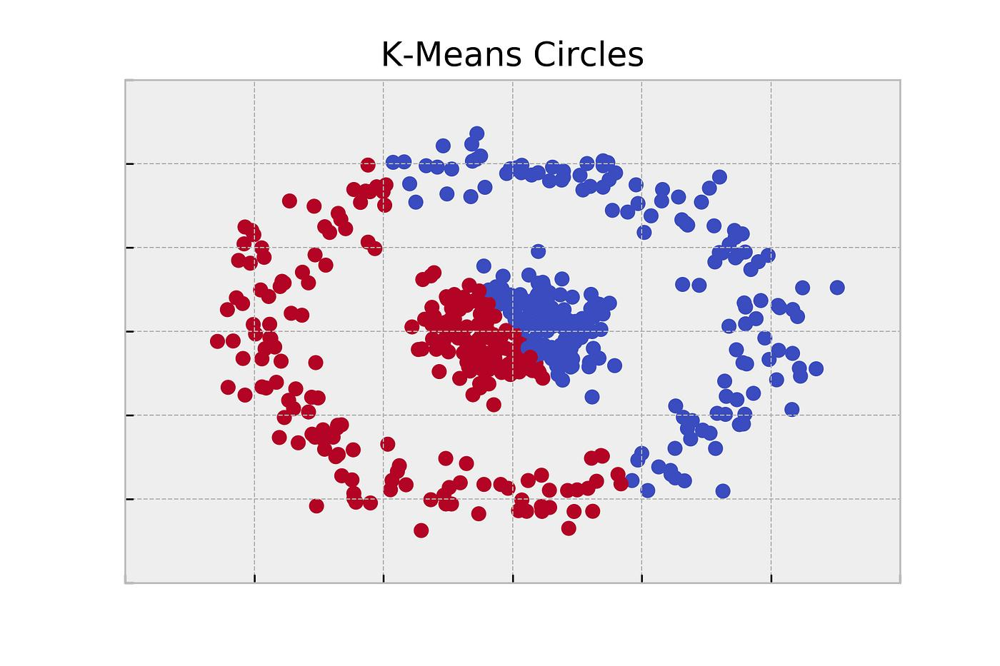
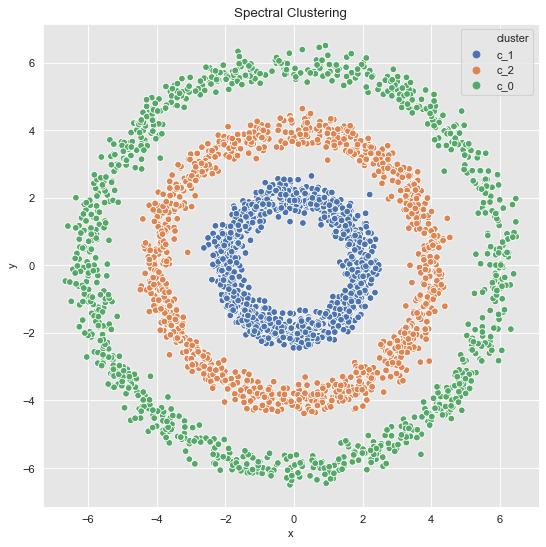
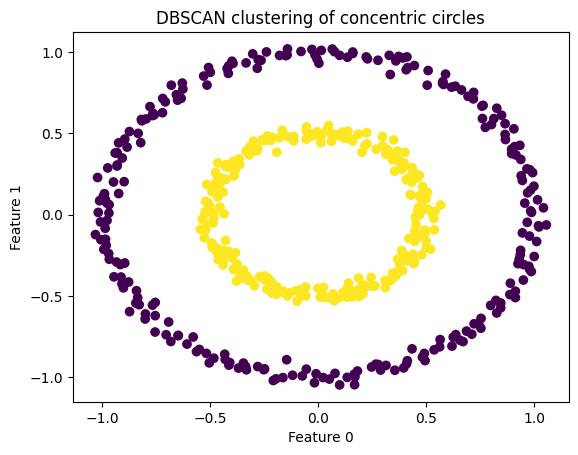

|Feature	|K-Means	|Spectral Clustering	|DBSCAN
:-----------|-----------|-----------------------|-------
Type|	Partition-based	Graph-based	Density-based
Nonlinear clusters|	Limited	|Excellent	|Excellent
Circular clusters|	Poor	|Good	|Good
Requires K|	Yes	|Yes	|No
Noise handling|	No|	No	|Yes
Scalable to large data|	Excellent	|Limited	|Moderate
Complexity|	Low|	High	|Moderate

14. Hyperparameter tuning

Spectral Clustering has important parameters that affect clustering quality.

Parameter|	Values to experiment
:--------|----------------------
n_clusters|	2, 3, 4, 5
gamma|	0.1, 0.5, 1, 5, 10, 15
n_neighbors|	5, 10, 15, 20
affinity|	rbf, nearest_neighbors

Example: Compare different cluster counts

c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


K=2, Silhouette=0.2243


c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


K=3, Silhouette=0.0768


c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


K=4, Silhouette=0.1251


c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


K=5, Silhouette=0.0916


c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


K=6, Silhouette=0.1439


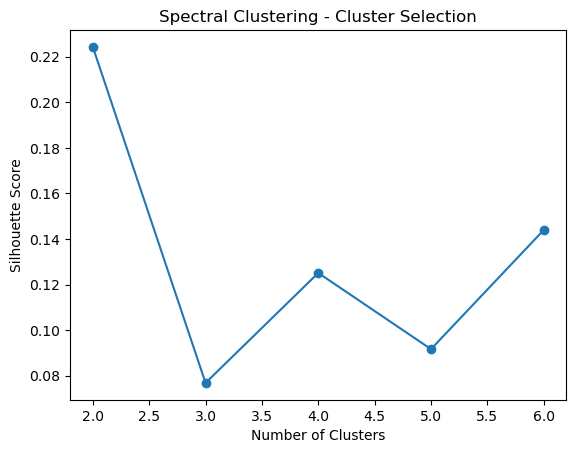

In [17]:

from sklearn.cluster import SpectralClustering
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

scores = []

for k in range(2, 7):

    model = SpectralClustering(
        n_clusters=k,
        affinity="rbf",
        gamma=10,
        random_state=42
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    scores.append(score)

    print(f"K={k}, Silhouette={score:.4f}")

plt.plot(range(2, 7), scores, marker="o")

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Spectral Clustering - Cluster Selection")

plt.show()


TThis helps identify a promising cluster count.

Note that Silhouette Score is not always sufficient for non-convex clusters; visual inspection and domain interpretation are also important.

15. Clustering evaluation metrics

Metric|	Purpose|	Best value
:-----|--------|-----------------------
Silhouette Score|	Cluster separation	|Higher
Davies-Bouldin Index|	Cluster similarity	|Lower
Calinski-Harabasz Score|	Cluster separation	|Higher
Adjusted Rand Index|	Compare against true labels	|Higher
Normalized Mutual Information|	Compare against true labels	|Higher

Evaluation code

In [18]:

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

print("Silhouette:", silhouette_score(X_scaled, labels))

print("Davies-Bouldin:",davies_bouldin_score(X_scaled, labels))

print("Calinski-Harabasz:",calinski_harabasz_score(X_scaled, labels))


Silhouette: 0.14392276546855204
Davies-Bouldin: 1.0405705898034618
Calinski-Harabasz: 73.59661412060892


16. Five practice assignments

Try implementing these yourself.

Assignment 1
Retail Customer Segmentation


Use Annual Income, Spending Score, and Age. Compare 3, 4, and 5 clusters.


Assignment 2
Student Performance

Use Study Hours, Attendance, and Exam Score. Analyze student groups.


Assignment 3
Employee Analytics

Use Experience, Working Hours, and Performance. Identify employee groups.


Assignment 4
E-Commerce Product Clustering

Use Price, Sales, and Rating. Analyze product patterns.


Assignment 5
Compare Spectral Clustering with K-Means

Use make_moons() and make_circles(). Compare clustering results and visualization.

17. Complete workflow summary

Spectral Clustering ML Workflow

1. Define the clustering problem
2. Load or generate dataset
3. Perform EDA
4. Visualize original data
5. Handle missing values and categorical features
6. Scale numerical features
7. Choose affinity method
8. Build similarity graph
9. Choose number of clusters
10. Fit Spectral Clustering
11. Generate cluster labels
12. Visualize clusters
13. Evaluate using Silhouette / Davies-Bouldin
14. Interpret cluster profiles
15. Document business insights

18. When should you use Spectral Clustering?

Use Spectral Clustering when:
- Your data contains nonlinear structures.
- K-Means fails to separate complex groups.
- You want graph-based clustering.
- Your dataset is reasonably small or medium-sized.
- You want to discover hidden structures in customer, student, or product data.

Avoid it when you have millions of observations unless you use an appropriate scalable approximation or graph implementation.

What I recommend learning next

Spectral Clustering vs K-Means vs DBSCAN

Compare all three algorithms on two moons, circles, and customer datasets with complete Python code.

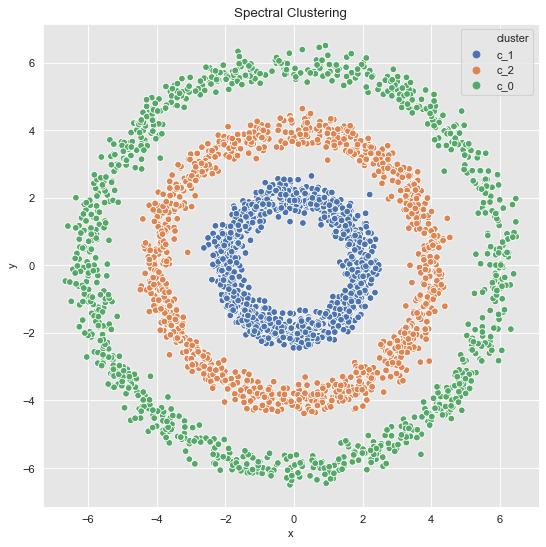

Spectral Clustering Advanced

Understand similarity matrices, graph Laplacians, eigenvalues, eigenvectors, and normalized spectral clustering with mathematical examples.

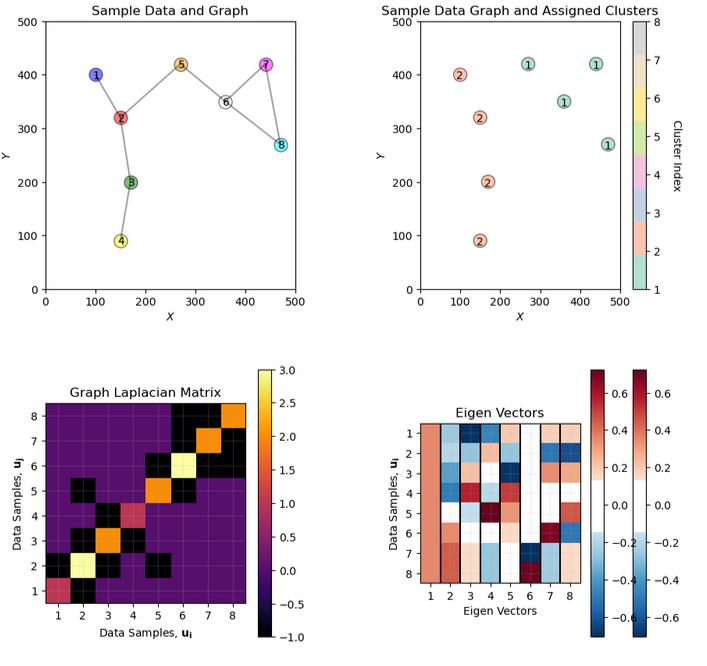

Spectral Clustering Project

Build an end-to-end customer segmentation project with real data, repository structure, visualization, evaluation, and interpretation.

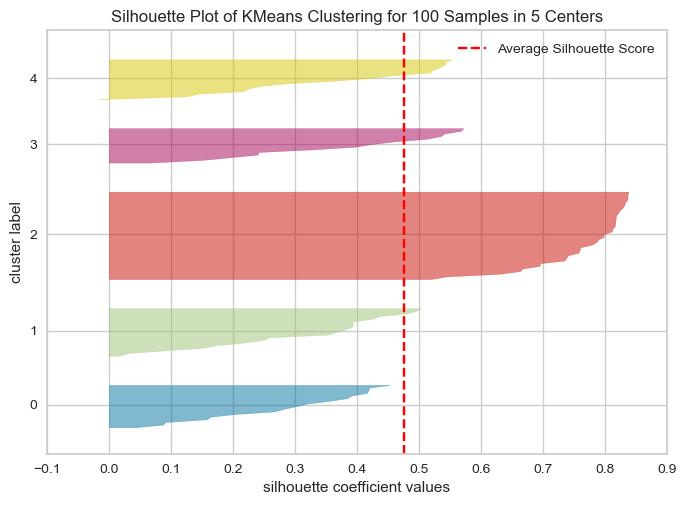

If you want, I can next provide 5 complete Spectral Clustering assignments with full runnable code, datasets, train/test experiments, visualization, and detailed line-by-line explanations in a single project-style tutorial.